In [26]:
%pip install -q pandas numpy matplotlib seaborn scikit-learn joblib xgboost

Note: you may need to restart the kernel to use updated packages.


C:\Users\adity\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\IPython\utils\_process_win32.py:131: ResourceWarning: unclosed file <_io.BufferedReader name=7>
  res = process_handler(cmd, _system_body)
C:\Users\adity\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\IPython\utils\_process_win32.py:131: ResourceWarning: unclosed file <_io.BufferedWriter name=5>
  res = process_handler(cmd, _system_body)
C:\Users\adity\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\IPython\utils\_process_win32.py:131: ResourceWarning: unclosed file <_io.BufferedReader name=6>
  res = process_handler(cmd, _system_body)


In [1]:
import json
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor
)

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

warnings.filterwarnings("ignore", category=FutureWarning)

try:
    from xgboost import XGBRegressor
    XGBOOST_AVAILABLE = True
except ImportError:
    XGBOOST_AVAILABLE = False

print("Libraries imported successfully.")
print("XGBoost available:", XGBOOST_AVAILABLE)

Libraries imported successfully.
XGBoost available: True


In [2]:
PROJECT_DIR = Path(
    r"C:\Users\adity\Downloads\Historical data\BharatMarket_AI"
)

FEATURE_DIR = PROJECT_DIR / "data" / "features"
REPORT_DIR = PROJECT_DIR / "outputs" / "reports"
CHART_DIR = PROJECT_DIR / "outputs" / "charts"
MODEL_DIR = PROJECT_DIR / "outputs" / "models"
FORECAST_DIR = PROJECT_DIR / "data" / "forecasts"

for folder in [
    FEATURE_DIR,
    REPORT_DIR,
    CHART_DIR,
    MODEL_DIR,
    FORECAST_DIR
]:
    folder.mkdir(parents=True, exist_ok=True)

INSTRUMENTS = [
    "NIFTY50",
    "BANKNIFTY",
    "RELIANCE",
    "TCS",
    "HDFCBANK",
    "INFY",
    "ICICIBANK",
    "SBIN",
    "ITC",
    "LT"
]

TARGET_COLUMN = "target_next_return"
PRICE_COLUMN = "close"

N_SPLITS = 6
INITIAL_TRAIN_RATIO = 0.80

print("Project directory:", PROJECT_DIR)
print("Number of instruments:", len(INSTRUMENTS))

Project directory: C:\Users\adity\Downloads\Historical data\BharatMarket_AI
Number of instruments: 10


In [3]:
def reconstruct_price(current_price, predicted_return_pct):

    return current_price * (
        1 + predicted_return_pct / 100
    )


example_current_price = 17833.349609
example_return = 0.577570

example_forecast = reconstruct_price(
    example_current_price,
    example_return
)

print("Current price:", example_current_price)
print("Predicted return (%):", example_return)
print("Reconstructed next price:", example_forecast)

Current price: 17833.349609
Predicted return (%): 0.57757
Reconstructed next price: 17936.349686336704


In [4]:
TARGET_COLUMNS = [
    "target_next_close",
    "target_next_return",
    "target_next_direction"
]

EXCLUDED_COLUMNS = [
    "date",
    "symbol",
    "instrument"
] + TARGET_COLUMNS


market_datasets = {}
dataset_summary = []

for symbol in INSTRUMENTS:

    file_path = FEATURE_DIR / f"{symbol}_model_ready.csv"

    if not file_path.exists():
        print("Missing:", file_path)
        continue

    df = pd.read_csv(file_path)

    df["date"] = pd.to_datetime(
        df["date"],
        errors="coerce"
    )

    df = (
        df.dropna(subset=["date"])
        .sort_values("date")
        .reset_index(drop=True)
    )

    for column in [
        TARGET_COLUMN,
        "target_next_close",
        PRICE_COLUMN
    ]:
        if column not in df.columns:
            raise ValueError(
                f"{symbol}: Missing required column {column}"
            )

        df[column] = pd.to_numeric(
            df[column],
            errors="coerce"
        )

    df = df.replace([np.inf, -np.inf], np.nan)

    # Require known next-day return and current close.
    df = df.dropna(
        subset=[TARGET_COLUMN, PRICE_COLUMN]
    ).reset_index(drop=True)

    # Numeric input features, excluding all target columns.
    feature_columns = [
        column
        for column in df.select_dtypes(include=np.number).columns
        if column not in EXCLUDED_COLUMNS
        and not column.startswith("target_")
        and not column.startswith("next_")
    ]

    X = df[feature_columns].copy()

    y_return = df[TARGET_COLUMN].copy()

    current_close = df[PRICE_COLUMN].copy()

    actual_next_close = df["target_next_close"].copy()

    dates = df["date"].copy()

    # Remove columns with no valid observations.
    feature_columns = [
        col for col in X.columns
        if X[col].notna().any()
    ]

    X = X[feature_columns]

    valid_rows = (
        X.notna().any(axis=1)
        & np.isfinite(y_return)
        & np.isfinite(current_close)
        & (current_close > 0)
        & np.isfinite(actual_next_close)
    )

    X = X.loc[valid_rows].reset_index(drop=True)
    y_return = y_return.loc[valid_rows].reset_index(drop=True)
    current_close = current_close.loc[valid_rows].reset_index(drop=True)
    actual_next_close = actual_next_close.loc[valid_rows].reset_index(drop=True)
    dates = dates.loc[valid_rows].reset_index(drop=True)

    market_datasets[symbol] = {
        "X": X,
        "y_return": y_return,
        "current_close": current_close,
        "actual_next_close": actual_next_close,
        "dates": dates,
        "features": feature_columns
    }

    dataset_summary.append({
        "Instrument": symbol,
        "Rows": len(X),
        "Features": len(feature_columns),
        "Start_Date": dates.min(),
        "End_Date": dates.max()
    })

dataset_summary_df = pd.DataFrame(dataset_summary)

display(dataset_summary_df)

print("Successfully loaded:", len(market_datasets))

,Instrument,Rows,Features,Start_Date,End_Date
0,NIFTY50,1034,62,2022-09-09,2026-11-20
1,BANKNIFTY,1033,62,2022-09-09,2026-11-20
2,RELIANCE,1037,62,2022-09-09,2026-11-20
3,TCS,1037,62,2022-09-09,2026-11-20
4,HDFCBANK,1037,62,2022-09-09,2026-11-20
5,INFY,1037,62,2022-09-09,2026-11-20
6,ICICIBANK,1037,62,2022-09-09,2026-11-20
7,SBIN,1037,62,2022-09-09,2026-11-20
8,ITC,1037,62,2022-09-09,2026-11-20
9,LT,1037,62,2022-09-09,2026-11-20


Successfully loaded: 10


In [5]:
def create_models():

    models = {

        "Linear Regression": Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
            ("model", LinearRegression())
        ]),

        "Decision Tree": Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("model", DecisionTreeRegressor(
                max_depth=6,
                min_samples_split=20,
                min_samples_leaf=10,
                random_state=42
            ))
        ]),

        "Random Forest": Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("model", RandomForestRegressor(
                n_estimators=100,
                max_depth=8,
                min_samples_split=20,
                min_samples_leaf=10,
                random_state=42,
                n_jobs=1
            ))
        ]),

        "Gradient Boosting": Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("model", GradientBoostingRegressor(
                n_estimators=100,
                learning_rate=0.03,
                max_depth=2,
                min_samples_split=20,
                min_samples_leaf=10,
                random_state=42
            ))
        ])
    }

    if XGBOOST_AVAILABLE:

        models["XGBoost"] = Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("model", XGBRegressor(
                n_estimators=100,
                learning_rate=0.03,
                max_depth=2,
                subsample=0.8,
                colsample_bytree=0.8,
                objective="reg:squarederror",
                random_state=42,
                n_jobs=1,
                verbosity=0
            ))
        ])

    return models


models = create_models()

print("Models configured:")

for name in models:
    print("-", name)

Models configured:
- Linear Regression
- Decision Tree
- Random Forest
- Gradient Boosting
- XGBoost


In [6]:
def generate_walk_forward_folds(
    number_of_rows,
    n_splits=6,
    initial_train_ratio=0.80
):

    initial_train_size = int(
        number_of_rows * initial_train_ratio
    )

    if initial_train_size < 300:
        raise ValueError(
            "At least 300 initial training observations required."
        )

    remaining_indices = np.arange(
        initial_train_size,
        number_of_rows
    )

    validation_blocks = np.array_split(
        remaining_indices,
        n_splits
    )

    folds = []

    for fold_number, validation_idx in enumerate(
        validation_blocks,
        start=1
    ):

        if len(validation_idx) == 0:
            continue

        train_idx = np.arange(
            validation_idx[0]
        )

        folds.append({
            "fold": fold_number,
            "train_idx": train_idx,
            "validation_idx": validation_idx
        })

    return folds


if "NIFTY50" in market_datasets:

    folds = generate_walk_forward_folds(
        len(market_datasets["NIFTY50"]["X"]),
        N_SPLITS,
        INITIAL_TRAIN_RATIO
    )

    for fold in folds:

        print(
            f"Fold {fold['fold']} | "
            f"Train: {len(fold['train_idx'])} | "
            f"Validation: {len(fold['validation_idx'])}"
        )

Fold 1 | Train: 827 | Validation: 35
Fold 2 | Train: 862 | Validation: 35
Fold 3 | Train: 897 | Validation: 35
Fold 4 | Train: 932 | Validation: 34
Fold 5 | Train: 966 | Validation: 34
Fold 6 | Train: 1000 | Validation: 34


In [7]:
def calculate_forecast_metrics(
    actual_return,
    predicted_return,
    current_close,
    actual_next_close
):

    actual_return = np.asarray(actual_return, dtype=float)
    predicted_return = np.asarray(predicted_return, dtype=float)
    current_close = np.asarray(current_close, dtype=float)
    actual_next_close = np.asarray(actual_next_close, dtype=float)

    predicted_close = reconstruct_price(
        current_close,
        predicted_return
    )

    return_mae = mean_absolute_error(
        actual_return,
        predicted_return
    )

    return_rmse = np.sqrt(
        mean_squared_error(
            actual_return,
            predicted_return
        )
    )

    price_mae = mean_absolute_error(
        actual_next_close,
        predicted_close
    )

    price_rmse = np.sqrt(
        mean_squared_error(
            actual_next_close,
            predicted_close
        )
    )

    if len(actual_next_close) > 1:
        price_r2 = r2_score(
            actual_next_close,
            predicted_close
        )
    else:
        price_r2 = np.nan

    # Directional accuracy only for non-neutral forecasts.
    directional_mask = np.abs(predicted_return) > 1e-12

    if directional_mask.any():

        actual_direction = np.sign(
            actual_return[directional_mask]
        )

        predicted_direction = np.sign(
            predicted_return[directional_mask]
        )

        directional_accuracy = np.mean(
            actual_direction == predicted_direction
        ) * 100

    else:
        directional_accuracy = np.nan

    coverage = np.mean(directional_mask) * 100

    return {
        "Return_MAE": return_mae,
        "Return_RMSE": return_rmse,
        "Price_MAE": price_mae,
        "Price_RMSE": price_rmse,
        "Price_R2": price_r2,
        "Directional_Accuracy": directional_accuracy,
        "Directional_Coverage_Pct": coverage
    }


print("Evaluation metrics created.")

Evaluation metrics created.


In [8]:
walk_forward_results = []
walk_forward_predictions = []
feature_importance_records = []

for symbol, dataset in market_datasets.items():

    print("\n" + "=" * 70)
    print("PROCESSING:", symbol)
    print("=" * 70)

    X = dataset["X"]
    y = dataset["y_return"]
    current_close = dataset["current_close"]
    actual_next_close = dataset["actual_next_close"]
    dates = dataset["dates"]

    folds = generate_walk_forward_folds(
        len(X),
        N_SPLITS,
        INITIAL_TRAIN_RATIO
    )

    for fold in folds:

        fold_number = fold["fold"]

        train_idx = fold["train_idx"]
        validation_idx = fold["validation_idx"]

        X_train = X.iloc[train_idx]
        y_train = y.iloc[train_idx]

        X_validation = X.iloc[validation_idx]
        y_validation = y.iloc[validation_idx]

        close_validation = current_close.iloc[validation_idx]
        actual_close_validation = actual_next_close.iloc[validation_idx]

        validation_dates = dates.iloc[validation_idx]

        print(
            f"\nFold {fold_number} | "
            f"Training={len(train_idx)} | "
            f"Validation={len(validation_idx)}"
        )

        # Zero-return baseline:
        # Predict no percentage change.
        baseline_predictions = np.zeros(
            len(validation_idx)
        )

        baseline_metrics = calculate_forecast_metrics(
            y_validation.values,
            baseline_predictions,
            close_validation.values,
            actual_close_validation.values
        )

        walk_forward_results.append({
            "Instrument": symbol,
            "Fold": fold_number,
            "Model": "Zero Return Baseline",
            "Train_Size": len(train_idx),
            "Validation_Size": len(validation_idx),
            **baseline_metrics
        })

        for model_name, model in models.items():

            try:

                model.fit(
                    X_train,
                    y_train
                )

                predictions = model.predict(
                    X_validation
                )

                predictions = np.asarray(
                    predictions,
                    dtype=float
                )

                predictions = np.nan_to_num(
                    predictions,
                    nan=0.0,
                    posinf=0.0,
                    neginf=0.0
                )

                metrics = calculate_forecast_metrics(
                    y_validation.values,
                    predictions,
                    close_validation.values,
                    actual_close_validation.values
                )

                walk_forward_results.append({
                    "Instrument": symbol,
                    "Fold": fold_number,
                    "Model": model_name,
                    "Train_Size": len(train_idx),
                    "Validation_Size": len(validation_idx),
                    **metrics
                })

                predicted_close = reconstruct_price(
                    close_validation.values,
                    predictions
                )

                for i in range(len(predictions)):

                    walk_forward_predictions.append({
                        "Instrument": symbol,
                        "Fold": fold_number,
                        "Date": validation_dates.iloc[i],
                        "Model": model_name,
                        "Current_Close": close_validation.iloc[i],
                        "Actual_Next_Return_Pct": y_validation.iloc[i],
                        "Predicted_Next_Return_Pct": predictions[i],
                        "Actual_Next_Close": actual_close_validation.iloc[i],
                        "Predicted_Next_Close": predicted_close[i],
                        "Prediction_Error": (
                            actual_close_validation.iloc[i]
                            - predicted_close[i]
                        )
                    })

                # Feature importance for tree models.
                fitted_model = model.named_steps["model"]

                if hasattr(fitted_model, "feature_importances_"):

                    for feature, importance in zip(
                        X.columns,
                        fitted_model.feature_importances_
                    ):

                        feature_importance_records.append({
                            "Instrument": symbol,
                            "Fold": fold_number,
                            "Model": model_name,
                            "Feature": feature,
                            "Importance": importance
                        })

                print(
                    f"{model_name}: completed | "
                    f"Price RMSE={metrics['Price_RMSE']:.4f} | "
                    f"Return MAE={metrics['Return_MAE']:.4f}"
                )

            except Exception as error:

                print(
                    f"{model_name}: FAILED | {error}"
                )

print("\nReturn-based walk-forward validation completed.")


PROCESSING: NIFTY50

Fold 1 | Training=827 | Validation=35
Linear Regression: completed | Price RMSE=357.2530 | Return MAE=1.0657
Decision Tree: completed | Price RMSE=264.5258 | Return MAE=0.8588
Random Forest: completed | Price RMSE=256.6289 | Return MAE=0.8184
Gradient Boosting: completed | Price RMSE=270.2103 | Return MAE=0.8141
XGBoost: completed | Price RMSE=265.6273 | Return MAE=0.8286

Fold 2 | Training=862 | Validation=35
Linear Regression: completed | Price RMSE=400.0433 | Return MAE=1.2140
Decision Tree: completed | Price RMSE=403.4283 | Return MAE=1.2983
Random Forest: completed | Price RMSE=369.7913 | Return MAE=1.1725
Gradient Boosting: completed | Price RMSE=353.1182 | Return MAE=1.1534
XGBoost: completed | Price RMSE=347.5978 | Return MAE=1.0868

Fold 3 | Training=897 | Validation=35
Linear Regression: completed | Price RMSE=216.3381 | Return MAE=0.7192
Decision Tree: completed | Price RMSE=208.6869 | Return MAE=0.6701
Random Forest: completed | Price RMSE=190.2275 | R

In [9]:
walk_forward_df = pd.DataFrame(
    walk_forward_results
)

walk_forward_predictions_df = pd.DataFrame(
    walk_forward_predictions
)

feature_importance_df = pd.DataFrame(
    feature_importance_records
)

if walk_forward_df.empty:
    raise RuntimeError(
        "No validation results were generated."
    )

walk_forward_df.to_csv(
    REPORT_DIR / "return_based_walk_forward_results.csv",
    index=False
)

walk_forward_predictions_df.to_csv(
    FORECAST_DIR / "return_based_walk_forward_predictions.csv",
    index=False
)

feature_importance_df.to_csv(
    REPORT_DIR / "return_based_feature_importance.csv",
    index=False
)

print("Evaluation records:", len(walk_forward_df))
print("Prediction records:", len(walk_forward_predictions_df))

print("\nFold count per instrument:")

display(
    walk_forward_df.groupby("Instrument")["Fold"].nunique()
)

display(walk_forward_df.head(20))

Evaluation records: 360
Prediction records: 10390

Fold count per instrument:


Instrument
BANKNIFTY    6
HDFCBANK     6
ICICIBANK    6
INFY         6
ITC          6
LT           6
NIFTY50      6
RELIANCE     6
SBIN         6
TCS          6
Name: Fold, dtype: int64

,Instrument,Fold,Model,Train_Size,Validation_Size,Return_MAE,Return_RMSE,Price_MAE,Price_RMSE,Price_R2,Directional_Accuracy,Directional_Coverage_Pct
0,NIFTY50,1,Zero Return Baseline,827,35,0.807410,0.986677,203.335658,247.642035,0.782493,NaN,0.0
1,NIFTY50,1,Linear Regression,827,35,1.065693,1.433068,267.918357,357.253018,0.547335,51.428571,100.0
2,NIFTY50,1,Decision Tree,827,35,0.858797,1.055289,216.578933,264.525810,0.751823,42.857143,100.0
3,NIFTY50,1,Random Forest,827,35,0.818389,1.022813,206.305752,256.628946,0.766420,40.000000,100.0
4,NIFTY50,1,Gradient Boosting,827,35,0.814080,1.077714,205.199485,270.210263,0.741043,57.142857,100.0
5,NIFTY50,1,XGBoost,827,35,0.828563,1.058978,208.905629,265.627323,0.749752,51.428571,100.0
6,NIFTY50,2,Zero Return Baseline,862,35,1.170431,1.435721,274.705636,335.436581,0.702234,NaN,0.0
7,NIFTY50,2,Linear Regression,862,35,1.213970,1.698990,286.405630,400.043259,0.576486,62.857143,100.0
8,NIFTY50,2,Decision Tree,862,35,1.298338,1.709744,307.095741,403.428322,0.569288,54.285714,100.0
9,NIFTY50,2,Random Forest,862,35,1.172477,1.571788,276.757903,369.791311,0.638118,57.142857,100.0


In [10]:
model_summary = (
    walk_forward_df
    .groupby(["Instrument", "Model"])
    .agg(
        Mean_Return_MAE=("Return_MAE", "mean"),
        Mean_Return_RMSE=("Return_RMSE", "mean"),
        Mean_Price_MAE=("Price_MAE", "mean"),
        Mean_Price_RMSE=("Price_RMSE", "mean"),
        Mean_Price_R2=("Price_R2", "mean"),
        Mean_Directional_Accuracy=("Directional_Accuracy", "mean"),
        Mean_Directional_Coverage=("Directional_Coverage_Pct", "mean"),
        Std_Price_RMSE=("Price_RMSE", "std")
    )
    .reset_index()
)

model_summary.to_csv(
    REPORT_DIR / "return_based_model_comparison.csv",
    index=False
)

display(model_summary)

best_models = (
    model_summary
    .sort_values(
        ["Instrument", "Mean_Price_RMSE"]
    )
    .groupby("Instrument")
    .first()
    .reset_index()
    .rename(columns={
        "Model": "Best_Model"
    })
)

best_models.to_csv(
    REPORT_DIR / "return_based_best_models.csv",
    index=False
)

print("\nBest model for each instrument:")

display(
    best_models[
        [
            "Instrument",
            "Best_Model",
            "Mean_Price_RMSE",
            "Mean_Return_MAE",
            "Mean_Directional_Accuracy"
        ]
    ]
)

print("\nModel selection counts:")

display(
    best_models["Best_Model"].value_counts()
)

,Instrument,Model,Mean_Return_MAE,Mean_Return_RMSE,Mean_Price_MAE,Mean_Price_RMSE,Mean_Price_R2,Mean_Directional_Accuracy,Mean_Directional_Coverage,Std_Price_RMSE
0,BANKNIFTY,Decision Tree,1.045692,1.359331,592.800500,769.237779,0.165087,51.148459,100.0,244.586401
1,BANKNIFTY,Gradient Boosting,0.946209,1.239567,536.053950,701.538882,0.552529,51.162465,100.0,215.354065
2,BANKNIFTY,Linear Regression,1.079209,1.373935,612.547715,780.108066,0.474470,50.196078,100.0,133.004923
3,BANKNIFTY,Random Forest,0.936241,1.220353,529.952472,690.226942,0.621122,48.851541,100.0,226.933684
4,BANKNIFTY,XGBoost,0.916152,1.205055,519.327231,682.487285,0.651410,45.420168,100.0,225.198462
5,BANKNIFTY,Zero Return Baseline,0.904039,1.176572,511.130521,664.688814,0.675160,NaN,0.0,226.332996
6,HDFCBANK,Decision Tree,1.247569,1.584614,9.775271,12.445968,0.701095,49.103641,100.0,2.848926
7,HDFCBANK,Gradient Boosting,1.215628,1.545031,9.529327,12.156736,0.722470,42.927171,100.0,3.166703
8,HDFCBANK,Linear Regression,1.303406,1.640663,10.272154,13.013179,0.692833,44.747899,100.0,3.084896
9,HDFCBANK,Random Forest,1.239557,1.564365,9.701329,12.293204,0.713782,45.266106,100.0,3.133737



Best model for each instrument:


,Instrument,Best_Model,Mean_Price_RMSE,Mean_Return_MAE,Mean_Directional_Accuracy
0,BANKNIFTY,Zero Return Baseline,664.688814,0.904039,45.420168
1,HDFCBANK,Gradient Boosting,12.156736,1.215628,42.927171
2,ICICIBANK,Zero Return Baseline,18.621060,1.068465,45.658263
3,INFY,Zero Return Baseline,24.959613,1.568403,46.120448
4,ITC,Linear Regression,3.917680,1.031992,53.375350
5,LT,Zero Return Baseline,62.839851,1.211963,51.932773
6,NIFTY50,Zero Return Baseline,222.340956,0.741545,50.210084
7,RELIANCE,Gradient Boosting,20.104428,1.140419,50.056022
8,SBIN,Zero Return Baseline,16.918146,1.217975,49.453782
9,TCS,Zero Return Baseline,48.638510,1.458541,50.070028



Model selection counts:


Best_Model
Zero Return Baseline    7
Gradient Boosting       2
Linear Regression       1
Name: count, dtype: int64

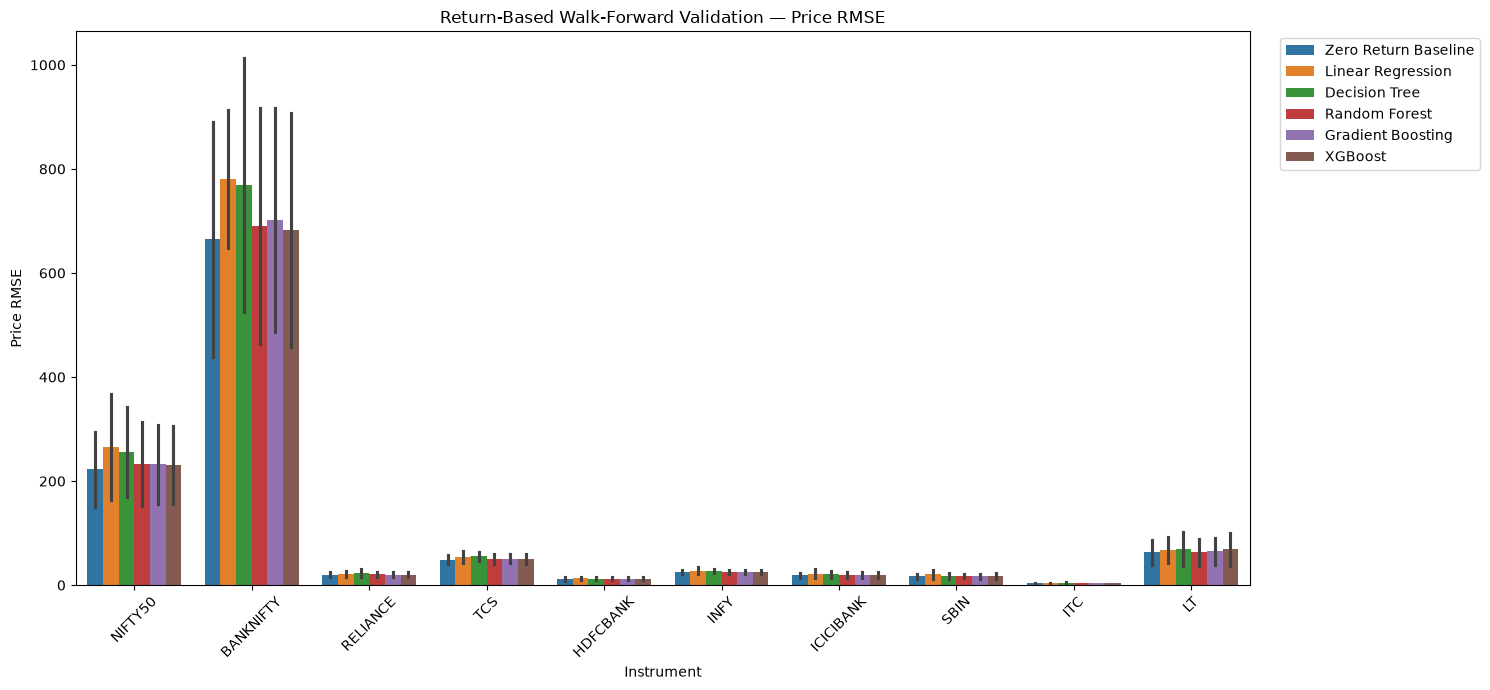

In [11]:
plt.figure(figsize=(15, 7))

sns.barplot(
    data=walk_forward_df,
    x="Instrument",
    y="Price_RMSE",
    hue="Model",
    errorbar="sd"
)

plt.title(
    "Return-Based Walk-Forward Validation — Price RMSE"
)

plt.xlabel("Instrument")
plt.ylabel("Price RMSE")
plt.xticks(rotation=45)

plt.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()

plt.savefig(
    CHART_DIR / "return_based_price_rmse_comparison.png",
    dpi=300
)

plt.show()

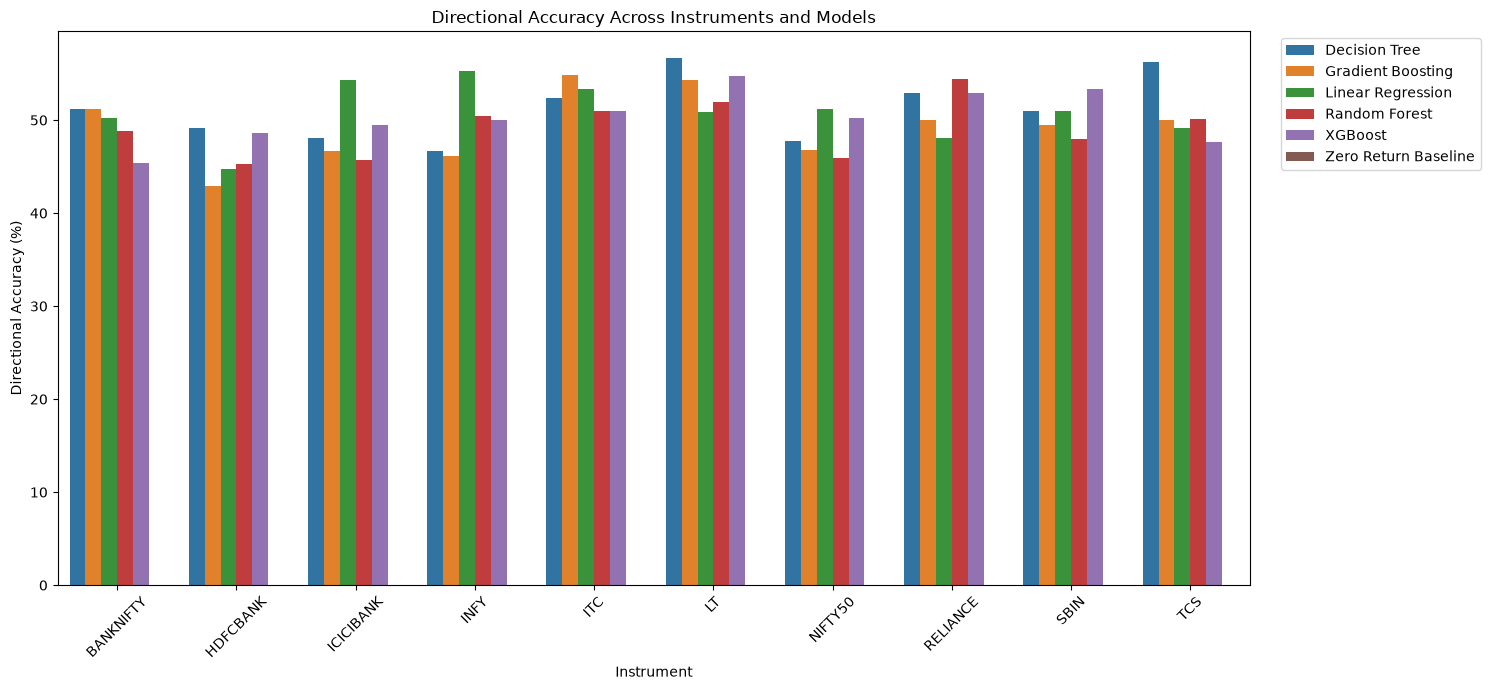

In [12]:
plt.figure(figsize=(15, 7))

sns.barplot(
    data=model_summary,
    x="Instrument",
    y="Mean_Directional_Accuracy",
    hue="Model"
)

plt.title(
    "Directional Accuracy Across Instruments and Models"
)

plt.xlabel("Instrument")
plt.ylabel("Directional Accuracy (%)")
plt.xticks(rotation=45)

plt.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()

plt.savefig(
    CHART_DIR / "return_based_directional_accuracy.png",
    dpi=300
)

plt.show()

In [13]:
nifty_predictions = walk_forward_predictions_df[
    walk_forward_predictions_df["Instrument"] == "NIFTY50"
]

if not nifty_predictions.empty:

    nifty_best = best_models[
        best_models["Instrument"] == "NIFTY50"
    ]["Best_Model"].iloc[0]

    if nifty_best == "Zero Return Baseline":

        plot_data = (
            nifty_predictions[
                nifty_predictions["Model"] == "Linear Regression"
            ]
            .sort_values("Date")
        )

        # If the baseline wins, show it directly from
        # its current-close benchmark.
        baseline_data = walk_forward_df[
            (walk_forward_df["Instrument"] == "NIFTY50")
            & (walk_forward_df["Model"] == "Zero Return Baseline")
        ]

        print(
            "Zero Return Baseline selected. "
            "See fold metrics for its benchmark performance."
        )

    else:

        plot_data = nifty_predictions[
            nifty_predictions["Model"] == nifty_best
        ].sort_values("Date")

        plt.figure(figsize=(15, 6))

        plt.plot(
            plot_data["Date"],
            plot_data["Actual_Next_Close"],
            label="Actual Next Close"
        )

        plt.plot(
            plot_data["Date"],
            plot_data["Predicted_Next_Close"],
            label="Predicted Next Close"
        )

        plt.title(
            f"NIFTY50 Actual vs Predicted — {nifty_best}"
        )

        plt.xlabel("Date")
        plt.ylabel("Closing Price")
        plt.legend()
        plt.grid(alpha=0.3)
        plt.tight_layout()

        plt.savefig(
            CHART_DIR / "return_based_nifty50_actual_vs_predicted.png",
            dpi=300
        )

        plt.show()

Zero Return Baseline selected. See fold metrics for its benchmark performance.


In [14]:
if not feature_importance_df.empty:

    importance_summary = (
        feature_importance_df
        .groupby(
            ["Instrument", "Model", "Feature"]
        )["Importance"]
        .mean()
        .reset_index()
    )

    importance_summary.to_csv(
        REPORT_DIR / "return_based_average_feature_importance.csv",
        index=False
    )

    nifty_importance = importance_summary[
        importance_summary["Instrument"] == "NIFTY50"
    ]

    if not nifty_importance.empty:

        selected_model = (
            best_models[
                best_models["Instrument"] == "NIFTY50"
            ]["Best_Model"].iloc[0]
        )

        if selected_model != "Zero Return Baseline":

            selected_importance = nifty_importance[
                nifty_importance["Model"] == selected_model
            ].nlargest(15, "Importance")

            plt.figure(figsize=(10, 7))

            sns.barplot(
                data=selected_importance,
                x="Importance",
                y="Feature"
            )

            plt.title(
                f"NIFTY50 Feature Importance — {selected_model}"
            )

            plt.tight_layout()

            plt.savefig(
                CHART_DIR / "return_based_nifty50_feature_importance.png",
                dpi=300
            )

            plt.show()

    display(importance_summary.head(20))

else:

    print("No tree-based feature importance generated.")

,Instrument,Model,Feature,Importance
0,BANKNIFTY,Decision Tree,adj_close,0.000000
1,BANKNIFTY,Decision Tree,atr_14,0.016356
2,BANKNIFTY,Decision Tree,atr_percentage,0.000000
3,BANKNIFTY,Decision Tree,bb_lower,0.000000
4,BANKNIFTY,Decision Tree,bb_middle,0.000000
5,BANKNIFTY,Decision Tree,bb_position,0.005097
6,BANKNIFTY,Decision Tree,bb_upper,0.000000
7,BANKNIFTY,Decision Tree,bb_width,0.012769
8,BANKNIFTY,Decision Tree,candle_body,0.000000
9,BANKNIFTY,Decision Tree,candle_body_percentage,0.000000


In [15]:
final_model_records = []

for symbol, dataset in market_datasets.items():

    selected = best_models[
        best_models["Instrument"] == symbol
    ]

    if selected.empty:
        continue

    selected_model_name = selected["Best_Model"].iloc[0]

    metadata = {
        "instrument": symbol,
        "target": "target_next_return",
        "target_unit": "percentage_points",
        "prediction_type": "next_trading_day_return",
        "selected_model": selected_model_name,
        "selection_metric": "Mean_Price_RMSE",
        "selected_model_price_rmse": float(
            selected["Mean_Price_RMSE"].iloc[0]
        )
    }

    metadata_path = (
        MODEL_DIR / f"{symbol}_return_model_metadata.json"
    )

    if selected_model_name == "Zero Return Baseline":

        metadata["model_file"] = None

        print(
            f"{symbol}: zero-return baseline selected. "
            "No ML model saved."
        )

    else:

        final_model = create_models()[selected_model_name]

        final_model.fit(
            dataset["X"],
            dataset["y_return"]
        )

        model_path = (
            MODEL_DIR
            / f"{symbol}_{selected_model_name.replace(' ', '_')}_return.joblib"
        )

        joblib.dump(
            final_model,
            model_path
        )

        feature_path = (
            MODEL_DIR / f"{symbol}_return_model_features.json"
        )

        with open(
            feature_path,
            "w",
            encoding="utf-8"
        ) as file:

            json.dump(
                dataset["features"],
                file,
                indent=4
            )

        metadata["model_file"] = str(model_path)
        metadata["feature_file"] = str(feature_path)

        print(
            f"{symbol}: saved {selected_model_name}"
        )

    with open(
        metadata_path,
        "w",
        encoding="utf-8"
    ) as file:

        json.dump(
            metadata,
            file,
            indent=4
        )

    final_model_records.append(metadata)


final_model_summary = pd.DataFrame(
    final_model_records
)

final_model_summary.to_csv(
    REPORT_DIR / "return_based_final_models.csv",
    index=False
)

display(final_model_summary)

NIFTY50: zero-return baseline selected. No ML model saved.
BANKNIFTY: zero-return baseline selected. No ML model saved.
RELIANCE: saved Gradient Boosting
TCS: zero-return baseline selected. No ML model saved.
HDFCBANK: saved Gradient Boosting
INFY: zero-return baseline selected. No ML model saved.
ICICIBANK: zero-return baseline selected. No ML model saved.
SBIN: zero-return baseline selected. No ML model saved.
ITC: saved Linear Regression
LT: zero-return baseline selected. No ML model saved.


,instrument,target,target_unit,prediction_type,selected_model,selection_metric,selected_model_price_rmse,model_file,feature_file
0,NIFTY50,target_next_return,percentage_points,next_trading_day_return,Zero Return Baseline,Mean_Price_RMSE,222.340956,NaN,NaN
1,BANKNIFTY,target_next_return,percentage_points,next_trading_day_return,Zero Return Baseline,Mean_Price_RMSE,664.688814,NaN,NaN
2,RELIANCE,target_next_return,percentage_points,next_trading_day_return,Gradient Boosting,Mean_Price_RMSE,20.104428,C:\Users\adity\Downloads\Historical data\Bhara...,C:\Users\adity\Downloads\Historical data\Bhara...
3,TCS,target_next_return,percentage_points,next_trading_day_return,Zero Return Baseline,Mean_Price_RMSE,48.638510,NaN,NaN
4,HDFCBANK,target_next_return,percentage_points,next_trading_day_return,Gradient Boosting,Mean_Price_RMSE,12.156736,C:\Users\adity\Downloads\Historical data\Bhara...,C:\Users\adity\Downloads\Historical data\Bhara...
5,INFY,target_next_return,percentage_points,next_trading_day_return,Zero Return Baseline,Mean_Price_RMSE,24.959613,NaN,NaN
6,ICICIBANK,target_next_return,percentage_points,next_trading_day_return,Zero Return Baseline,Mean_Price_RMSE,18.621060,NaN,NaN
7,SBIN,target_next_return,percentage_points,next_trading_day_return,Zero Return Baseline,Mean_Price_RMSE,16.918146,NaN,NaN
8,ITC,target_next_return,percentage_points,next_trading_day_return,Linear Regression,Mean_Price_RMSE,3.917680,C:\Users\adity\Downloads\Historical data\Bhara...,C:\Users\adity\Downloads\Historical data\Bhara...
9,LT,target_next_return,percentage_points,next_trading_day_return,Zero Return Baseline,Mean_Price_RMSE,62.839851,NaN,NaN


In [16]:
print("=" * 70)
print("BHARATMARKET AI — RETURN-BASED MACHINE LEARNING")
print("=" * 70)

print("\nInstruments loaded:", len(market_datasets))
print("Models tested:", len(models))
print("Walk-forward folds:", N_SPLITS)

print(
    "\nEvaluation records:",
    len(walk_forward_df)
)

print(
    "Prediction records:",
    len(walk_forward_predictions_df)
)

print("\nBest model selection:")

display(
    best_models[
        [
            "Instrument",
            "Best_Model",
            "Mean_Price_RMSE",
            "Mean_Return_MAE",
            "Mean_Directional_Accuracy"
        ]
    ]
)

print("\nFinal model files:")

display(final_model_summary)

print("\nReports:", REPORT_DIR)
print("Charts:", CHART_DIR)
print("Models:", MODEL_DIR)
print("Forecasts:", FORECAST_DIR)

print("\nNotebook 08 return-based experiment completed.")

BHARATMARKET AI — RETURN-BASED MACHINE LEARNING

Instruments loaded: 10
Models tested: 5
Walk-forward folds: 6

Evaluation records: 360
Prediction records: 10390

Best model selection:


,Instrument,Best_Model,Mean_Price_RMSE,Mean_Return_MAE,Mean_Directional_Accuracy
0,BANKNIFTY,Zero Return Baseline,664.688814,0.904039,45.420168
1,HDFCBANK,Gradient Boosting,12.156736,1.215628,42.927171
2,ICICIBANK,Zero Return Baseline,18.621060,1.068465,45.658263
3,INFY,Zero Return Baseline,24.959613,1.568403,46.120448
4,ITC,Linear Regression,3.917680,1.031992,53.375350
5,LT,Zero Return Baseline,62.839851,1.211963,51.932773
6,NIFTY50,Zero Return Baseline,222.340956,0.741545,50.210084
7,RELIANCE,Gradient Boosting,20.104428,1.140419,50.056022
8,SBIN,Zero Return Baseline,16.918146,1.217975,49.453782
9,TCS,Zero Return Baseline,48.638510,1.458541,50.070028



Final model files:


,instrument,target,target_unit,prediction_type,selected_model,selection_metric,selected_model_price_rmse,model_file,feature_file
0,NIFTY50,target_next_return,percentage_points,next_trading_day_return,Zero Return Baseline,Mean_Price_RMSE,222.340956,NaN,NaN
1,BANKNIFTY,target_next_return,percentage_points,next_trading_day_return,Zero Return Baseline,Mean_Price_RMSE,664.688814,NaN,NaN
2,RELIANCE,target_next_return,percentage_points,next_trading_day_return,Gradient Boosting,Mean_Price_RMSE,20.104428,C:\Users\adity\Downloads\Historical data\Bhara...,C:\Users\adity\Downloads\Historical data\Bhara...
3,TCS,target_next_return,percentage_points,next_trading_day_return,Zero Return Baseline,Mean_Price_RMSE,48.638510,NaN,NaN
4,HDFCBANK,target_next_return,percentage_points,next_trading_day_return,Gradient Boosting,Mean_Price_RMSE,12.156736,C:\Users\adity\Downloads\Historical data\Bhara...,C:\Users\adity\Downloads\Historical data\Bhara...
5,INFY,target_next_return,percentage_points,next_trading_day_return,Zero Return Baseline,Mean_Price_RMSE,24.959613,NaN,NaN
6,ICICIBANK,target_next_return,percentage_points,next_trading_day_return,Zero Return Baseline,Mean_Price_RMSE,18.621060,NaN,NaN
7,SBIN,target_next_return,percentage_points,next_trading_day_return,Zero Return Baseline,Mean_Price_RMSE,16.918146,NaN,NaN
8,ITC,target_next_return,percentage_points,next_trading_day_return,Linear Regression,Mean_Price_RMSE,3.917680,C:\Users\adity\Downloads\Historical data\Bhara...,C:\Users\adity\Downloads\Historical data\Bhara...
9,LT,target_next_return,percentage_points,next_trading_day_return,Zero Return Baseline,Mean_Price_RMSE,62.839851,NaN,NaN



Reports: C:\Users\adity\Downloads\Historical data\BharatMarket_AI\outputs\reports
Charts: C:\Users\adity\Downloads\Historical data\BharatMarket_AI\outputs\charts
Models: C:\Users\adity\Downloads\Historical data\BharatMarket_AI\outputs\models
Forecasts: C:\Users\adity\Downloads\Historical data\BharatMarket_AI\data\forecasts

Notebook 08 return-based experiment completed.


In [17]:
import pandas as pd
from pathlib import Path

PROJECT_DIR = Path(
    r"C:\Users\adity\Downloads\Historical data\BharatMarket_AI"
)

REPORT_DIR = PROJECT_DIR / "outputs" / "reports"
MODEL_DIR = PROJECT_DIR / "outputs" / "models"

best_models = pd.read_csv(
    REPORT_DIR / "return_based_best_models.csv"
)

fold_results = pd.read_csv(
    REPORT_DIR / "return_based_walk_forward_results.csv"
)

final_models = pd.read_csv(
    REPORT_DIR / "return_based_final_models.csv"
)

print("BEST MODEL PER INSTRUMENT")
display(best_models)

print("\nMODEL SELECTION COUNTS")
display(best_models["Best_Model"].value_counts())

print("\nVALIDATION FOLDS")
display(
    fold_results.groupby("Instrument")["Fold"].nunique()
)

print("\nSAVED FINAL MODELS")
display(final_models)

print("\nTOTAL INSTRUMENTS:", best_models["Instrument"].nunique())

BEST MODEL PER INSTRUMENT


,Instrument,Best_Model,Mean_Return_MAE,Mean_Return_RMSE,Mean_Price_MAE,Mean_Price_RMSE,Mean_Price_R2,Mean_Directional_Accuracy,Mean_Directional_Coverage,Std_Price_RMSE
0,BANKNIFTY,Zero Return Baseline,0.904039,1.176572,511.130521,664.688814,0.675160,45.420168,0.0,226.332996
1,HDFCBANK,Gradient Boosting,1.215628,1.545031,9.529327,12.156736,0.722470,42.927171,100.0,3.166703
2,ICICIBANK,Zero Return Baseline,1.068465,1.366950,14.525811,18.621060,0.799852,45.658263,0.0,4.889060
3,INFY,Zero Return Baseline,1.568403,2.084895,18.585570,24.959613,0.823525,46.120448,0.0,3.849441
4,ITC,Linear Regression,1.031992,1.360808,2.981302,3.917680,0.648470,53.375350,100.0,0.786501
5,LT,Zero Return Baseline,1.211963,1.618605,47.239478,62.839851,0.849786,51.932773,0.0,23.734058
6,NIFTY50,Zero Return Baseline,0.741545,0.930447,177.495055,222.340956,0.768894,50.210084,0.0,71.260458
7,RELIANCE,Gradient Boosting,1.140419,1.538755,15.058785,20.104428,0.659127,50.056022,100.0,5.022933
8,SBIN,Zero Return Baseline,1.217975,1.613797,12.736798,16.918146,0.784642,49.453782,0.0,4.206367
9,TCS,Zero Return Baseline,1.458541,2.004502,35.095549,48.638510,0.819678,50.070028,0.0,8.671471



MODEL SELECTION COUNTS


Best_Model
Zero Return Baseline    7
Gradient Boosting       2
Linear Regression       1
Name: count, dtype: int64


VALIDATION FOLDS


Instrument
BANKNIFTY    6
HDFCBANK     6
ICICIBANK    6
INFY         6
ITC          6
LT           6
NIFTY50      6
RELIANCE     6
SBIN         6
TCS          6
Name: Fold, dtype: int64


SAVED FINAL MODELS


,instrument,target,target_unit,prediction_type,selected_model,selection_metric,selected_model_price_rmse,model_file,feature_file
0,NIFTY50,target_next_return,percentage_points,next_trading_day_return,Zero Return Baseline,Mean_Price_RMSE,222.340956,NaN,NaN
1,BANKNIFTY,target_next_return,percentage_points,next_trading_day_return,Zero Return Baseline,Mean_Price_RMSE,664.688814,NaN,NaN
2,RELIANCE,target_next_return,percentage_points,next_trading_day_return,Gradient Boosting,Mean_Price_RMSE,20.104428,C:\Users\adity\Downloads\Historical data\Bhara...,C:\Users\adity\Downloads\Historical data\Bhara...
3,TCS,target_next_return,percentage_points,next_trading_day_return,Zero Return Baseline,Mean_Price_RMSE,48.638510,NaN,NaN
4,HDFCBANK,target_next_return,percentage_points,next_trading_day_return,Gradient Boosting,Mean_Price_RMSE,12.156736,C:\Users\adity\Downloads\Historical data\Bhara...,C:\Users\adity\Downloads\Historical data\Bhara...
5,INFY,target_next_return,percentage_points,next_trading_day_return,Zero Return Baseline,Mean_Price_RMSE,24.959613,NaN,NaN
6,ICICIBANK,target_next_return,percentage_points,next_trading_day_return,Zero Return Baseline,Mean_Price_RMSE,18.621060,NaN,NaN
7,SBIN,target_next_return,percentage_points,next_trading_day_return,Zero Return Baseline,Mean_Price_RMSE,16.918146,NaN,NaN
8,ITC,target_next_return,percentage_points,next_trading_day_return,Linear Regression,Mean_Price_RMSE,3.917680,C:\Users\adity\Downloads\Historical data\Bhara...,C:\Users\adity\Downloads\Historical data\Bhara...
9,LT,target_next_return,percentage_points,next_trading_day_return,Zero Return Baseline,Mean_Price_RMSE,62.839851,NaN,NaN



TOTAL INSTRUMENTS: 10
